In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/catalinagligor22/cardio/cardio_train.csv
/kaggle/input/datasets/orvile/carotid-ultrasound-images/dataset.csv
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071355560051VAS_slice_351.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121847410041VAS_slice_614.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071308300020EM VASCULAR_slice_695.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071314560026VAS_slice_65.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/C

 Imagini găsite: 1100
 Măști găsite:   1100
 Perechi valide: True

 Exemplu imagine: 202201121748100022VAS_slice_1069.png
 Exemplu mască:   202201121748100022VAS_slice_1069.png


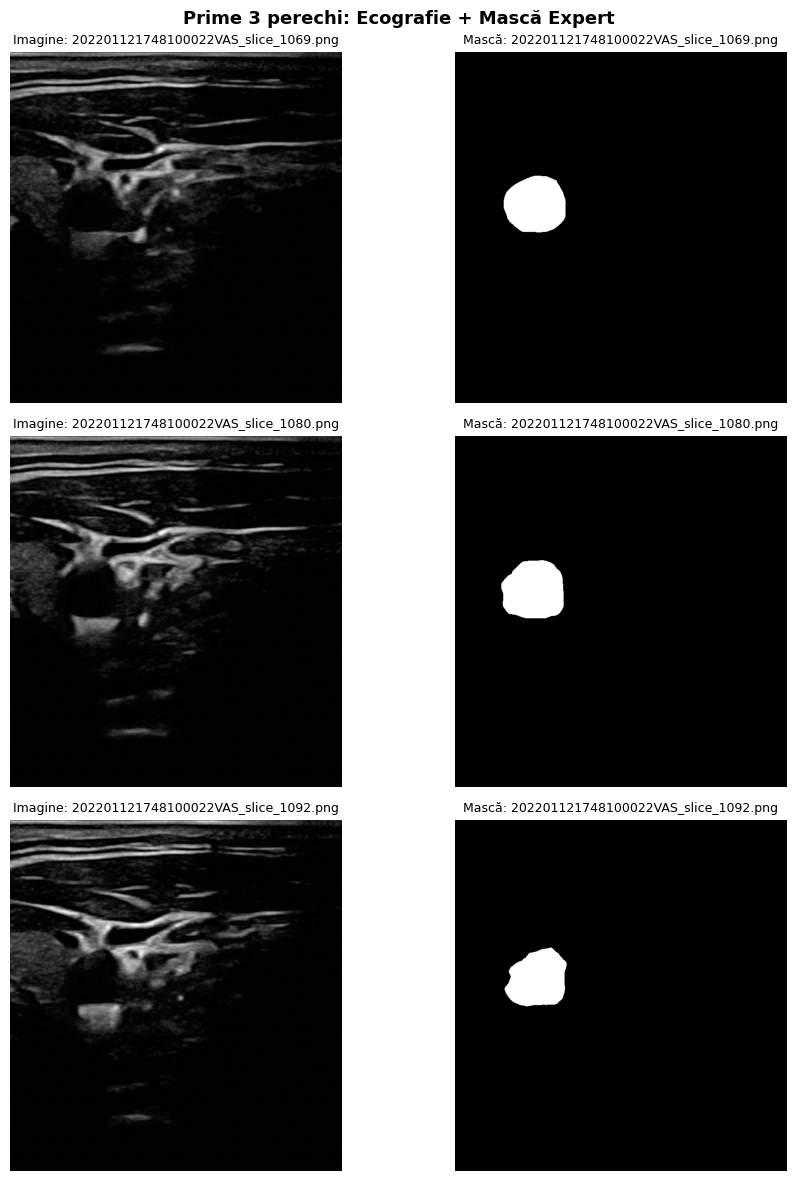

In [2]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd

# Căile corecte (le-ai găsit tu!)
IMAGES_PATH = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images"
MASKS_PATH  = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images"
CARDIO_PATH = "/kaggle/input/datasets/catalinagligor22/cardio/cardio_train.csv"

# Verificare de bază
images_list = sorted(os.listdir(IMAGES_PATH))
masks_list  = sorted(os.listdir(MASKS_PATH))

print(f" Imagini găsite: {len(images_list)}")
print(f" Măști găsite:   {len(masks_list)}")
print(f" Perechi valide: {len(images_list) == len(masks_list)}")
print(f"\n Exemplu imagine: {images_list[0]}")
print(f" Exemplu mască:   {masks_list[0]}")

# ✅ FIX: os.path.join în loc de concatenare cu +
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
for i in range(3):
    img  = np.array(Image.open(os.path.join(IMAGES_PATH, images_list[i])).convert('L'))
    mask = np.array(Image.open(os.path.join(MASKS_PATH,  masks_list[i])).convert('L'))

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'Imagine: {images_list[i]}', fontsize=9)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask, cmap='gray')
    axes[i, 1].set_title(f'Mască: {masks_list[i]}', fontsize=9)
    axes[i, 1].axis('off')

plt.suptitle('Prime 3 perechi: Ecografie + Mască Expert', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('first_look.png', dpi=150, bbox_inches='tight')
plt.show()

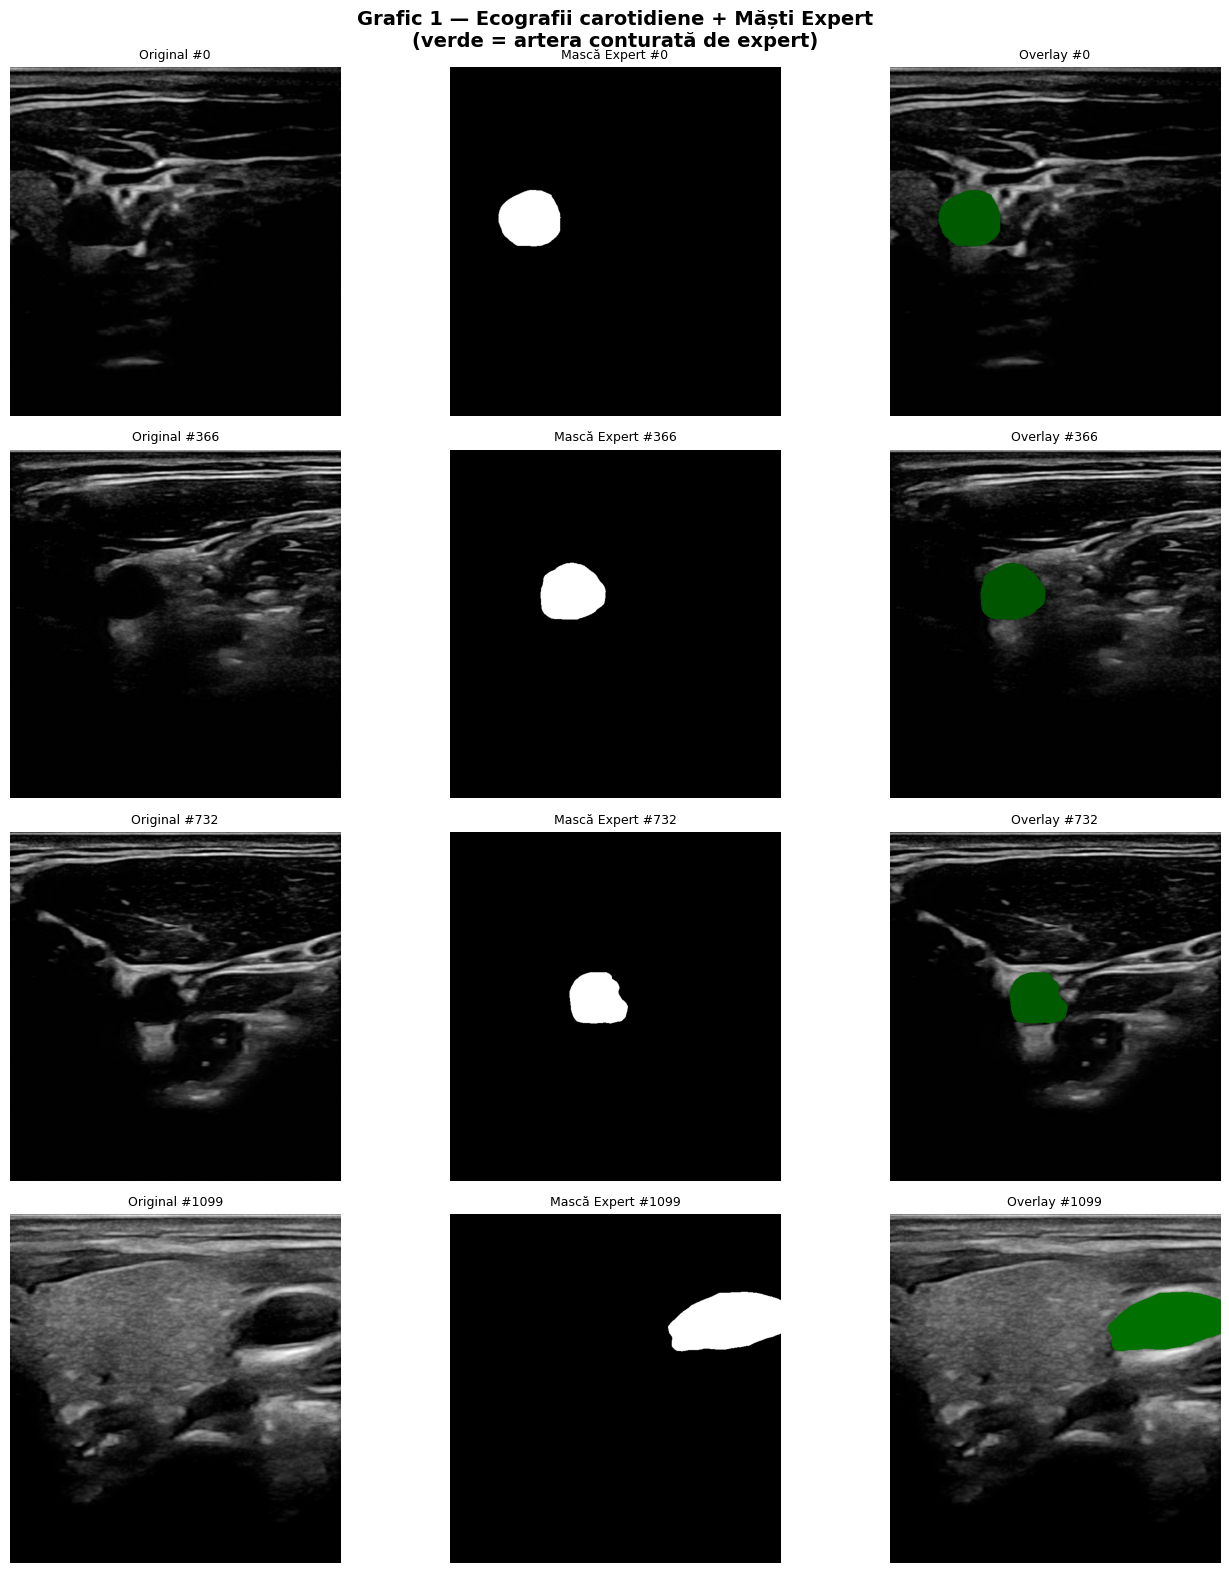

In [3]:
fig, axes = plt.subplots(4, 3, figsize=(14, 16))
fig.suptitle('Grafic 1 — Ecografii carotidiene + Măști Expert\n'
             '(verde = artera conturată de expert)', fontsize=14, fontweight='bold')

indices = np.linspace(0, len(images_list)-1, 4, dtype=int)

for row, idx in enumerate(indices):
    img  = np.array(Image.open(os.path.join(IMAGES_PATH, images_list[idx])).convert('L'))
    mask = np.array(Image.open(os.path.join(MASKS_PATH,  masks_list[idx])).convert('L'))

    # Overlay: imagine originală + mască în verde semitransparent
    img_rgb       = np.stack([img, img, img], axis=-1)
    overlay       = img_rgb.copy()
    mask_bool     = mask > 127
    overlay[mask_bool, 0] = 0
    overlay[mask_bool, 1] = min(255, img[mask_bool].mean().astype(int) + 80)
    overlay[mask_bool, 2] = 0

    axes[row, 0].imshow(img, cmap='gray')
    axes[row, 0].set_title(f'Original #{idx}', fontsize=9)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(mask, cmap='gray')
    axes[row, 1].set_title(f'Mască Expert #{idx}', fontsize=9)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f'Overlay #{idx}', fontsize=9)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('grafic1_mosaic.png', dpi=150, bbox_inches='tight')
plt.show()


   Dimensiuni imagini:
   Lățime  — min: 709, max: 709, medie: 709 px
   Înălțime — min: 749, max: 749, medie: 749 px
   Aspect ratio — min: 0.95, max: 0.95


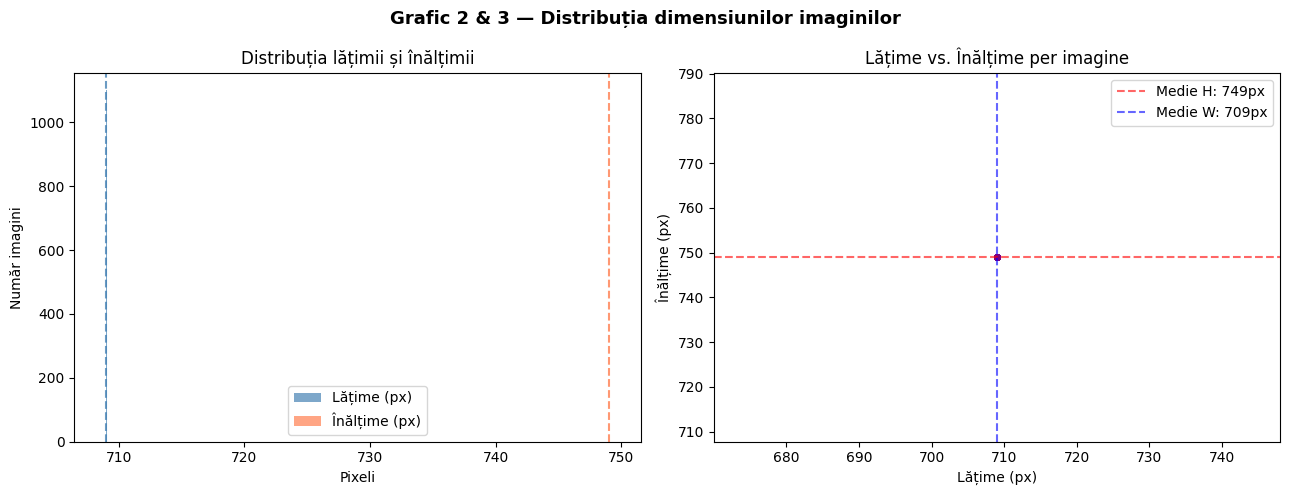

In [4]:
# Colectează dimensiunile tuturor imaginilor
widths, heights, aspect_ratios = [], [], []

for fname in images_list:
    img = Image.open(os.path.join(IMAGES_PATH, fname))
    w, h = img.size
    widths.append(w)
    heights.append(h)
    aspect_ratios.append(w / h)

print(f"   Dimensiuni imagini:")
print(f"   Lățime  — min: {min(widths)}, max: {max(widths)}, medie: {np.mean(widths):.0f} px")
print(f"   Înălțime — min: {min(heights)}, max: {max(heights)}, medie: {np.mean(heights):.0f} px")
print(f"   Aspect ratio — min: {min(aspect_ratios):.2f}, max: {max(aspect_ratios):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Grafic 2 & 3 — Distribuția dimensiunilor imaginilor', fontsize=13, fontweight='bold')

# Grafic 2 — Histogramă lățimi și înălțimi
axes[0].hist(widths,  bins=20, alpha=0.7, color='steelblue', label='Lățime (px)')
axes[0].hist(heights, bins=20, alpha=0.7, color='coral',     label='Înălțime (px)')
axes[0].set_xlabel('Pixeli')
axes[0].set_ylabel('Număr imagini')
axes[0].set_title('Distribuția lățimii și înălțimii')
axes[0].legend()
axes[0].axvline(np.mean(widths),  color='steelblue', linestyle='--', alpha=0.8, label=f'Medie lățime: {np.mean(widths):.0f}px')
axes[0].axvline(np.mean(heights), color='coral',     linestyle='--', alpha=0.8)

# Grafic 3 — Scatter lățime vs înălțime
axes[1].scatter(widths, heights, alpha=0.5, color='purple', s=15)
axes[1].set_xlabel('Lățime (px)')
axes[1].set_ylabel('Înălțime (px)')
axes[1].set_title('Lățime vs. Înălțime per imagine')
axes[1].axhline(np.mean(heights), color='red', linestyle='--', alpha=0.6, label=f'Medie H: {np.mean(heights):.0f}px')
axes[1].axvline(np.mean(widths),  color='blue', linestyle='--', alpha=0.6, label=f'Medie W: {np.mean(widths):.0f}px')
axes[1].legend()

plt.tight_layout()
plt.savefig('grafic2_3_dimensiuni.png', dpi=150, bbox_inches='tight')
plt.show()


📊 Acoperire mască (% pixeli = artera):
   Medie  : 2.35%
   Minim  : 1.31%
   Maxim  : 5.37%
   Std Dev: 0.51%


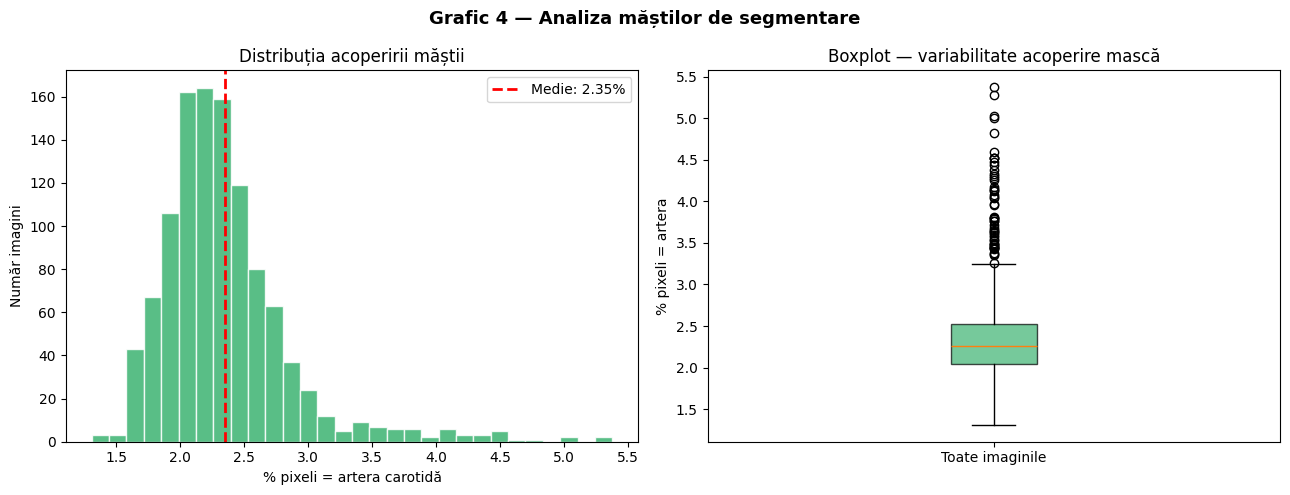

In [5]:
mask_coverage = []  # Procentul de pixeli = artera

for fname in masks_list:
    mask = np.array(Image.open(os.path.join(MASKS_PATH, fname)).convert('L'))
    total_pixels  = mask.size
    artery_pixels = (mask > 127).sum()
    mask_coverage.append((artery_pixels / total_pixels) * 100)

print(f"📊 Acoperire mască (% pixeli = artera):")
print(f"   Medie  : {np.mean(mask_coverage):.2f}%")
print(f"   Minim  : {np.min(mask_coverage):.2f}%")
print(f"   Maxim  : {np.max(mask_coverage):.2f}%")
print(f"   Std Dev: {np.std(mask_coverage):.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Grafic 4 — Analiza măștilor de segmentare', fontsize=13, fontweight='bold')

axes[0].hist(mask_coverage, bins=30, color='mediumseagreen', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(mask_coverage), color='red', linestyle='--', linewidth=2,
                label=f'Medie: {np.mean(mask_coverage):.2f}%')
axes[0].set_xlabel('% pixeli = artera carotidă')
axes[0].set_ylabel('Număr imagini')
axes[0].set_title('Distribuția acoperirii măștii')
axes[0].legend()

axes[1].boxplot(mask_coverage, patch_artist=True,
                boxprops=dict(facecolor='mediumseagreen', alpha=0.7))
axes[1].set_ylabel('% pixeli = artera')
axes[1].set_title('Boxplot — variabilitate acoperire mască')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Toate imaginile'])

plt.tight_layout()
plt.savefig('grafic4_masti.png', dpi=150, bbox_inches='tight')
plt.show()


Dataset clinice: 69649 pacienți, 15 coloane
       age_years     ap_hi     ap_lo       bmi  cholesterol
count   69649.00  69649.00  69649.00  69649.00     69649.00
mean       52.85    127.09     96.65     27.56         1.37
std         6.76     16.99    188.70      6.08         0.68
min        29.00     85.00      0.00      3.47         1.00
25%        48.00    120.00     80.00     23.88         1.00
50%        53.00    120.00     80.00     26.40         1.00
75%        58.00    140.00     90.00     30.25         2.00
max        64.00    240.00  11000.00    298.67         3.00


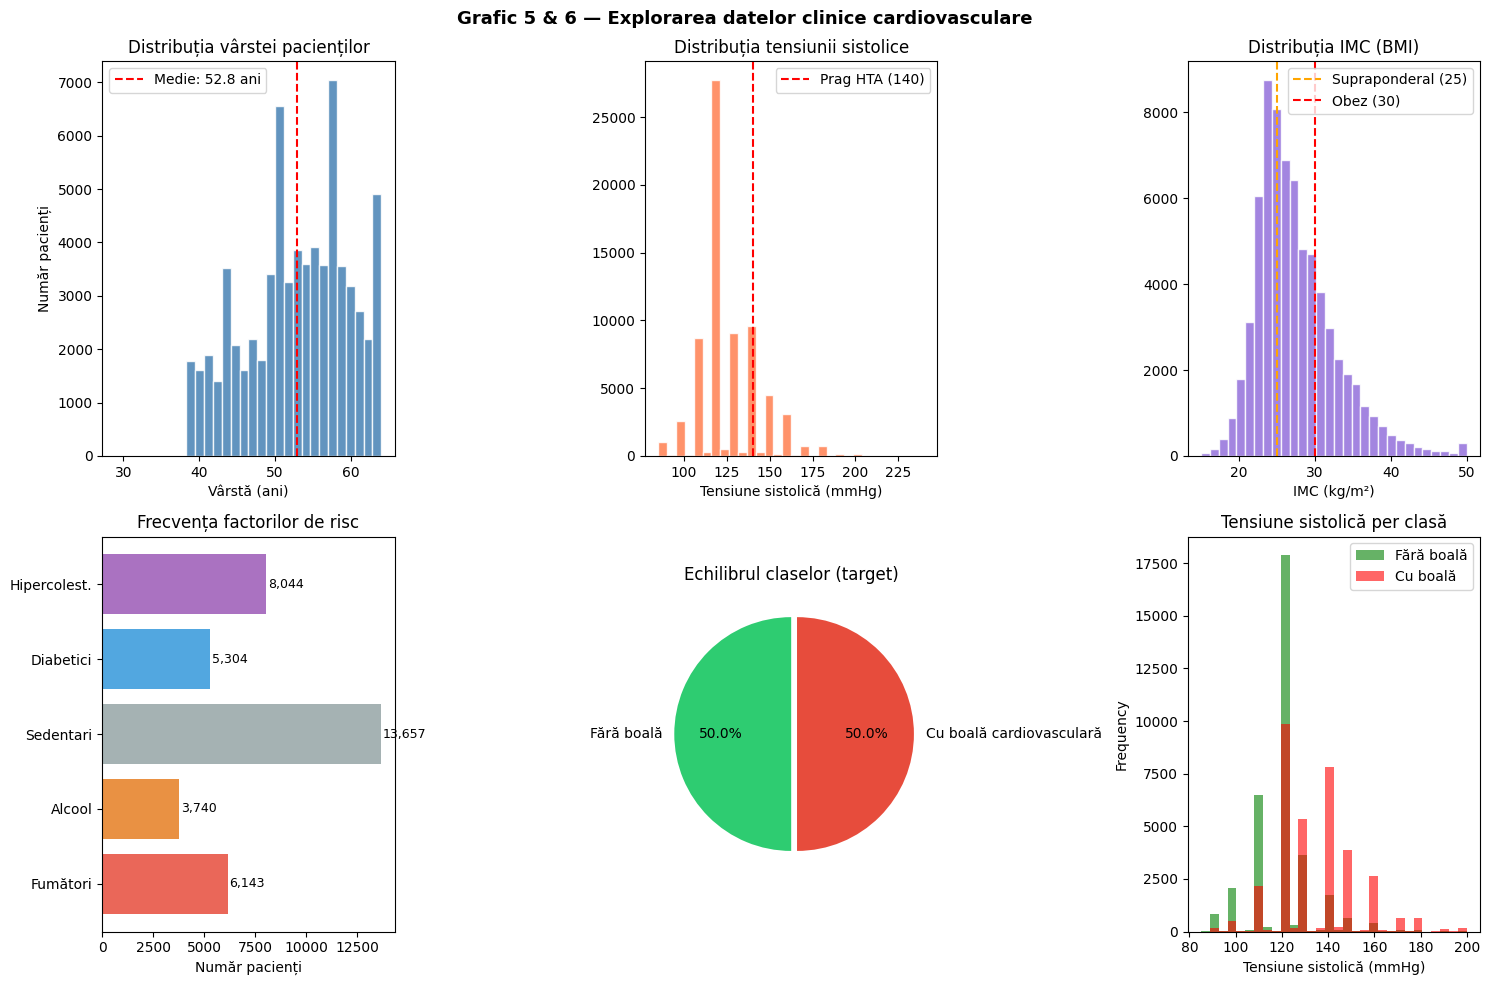

In [6]:
df = pd.read_csv(CARDIO_PATH, sep=';')

# Curățare rapidă pentru EDA
df['age_years'] = (df['age'] / 365).astype(int)
df['bmi']       = df['weight'] / ((df['height'] / 100) ** 2)
df              = df[(df['ap_hi'] > 80) & (df['ap_hi'] < 250)]   # elimini outlieri

print(f"Dataset clinice: {df.shape[0]} pacienți, {df.shape[1]} coloane")
print(df[['age_years', 'ap_hi', 'ap_lo', 'bmi', 'cholesterol']].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Grafic 5 & 6 — Explorarea datelor clinice cardiovasculare', fontsize=13, fontweight='bold')

# Distribuția vârstei
axes[0,0].hist(df['age_years'], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
axes[0,0].set_title('Distribuția vârstei pacienților')
axes[0,0].set_xlabel('Vârstă (ani)')
axes[0,0].set_ylabel('Număr pacienți')
axes[0,0].axvline(df['age_years'].mean(), color='red', linestyle='--',
                   label=f"Medie: {df['age_years'].mean():.1f} ani")
axes[0,0].legend()

# Distribuția tensiunii arteriale
axes[0,1].hist(df['ap_hi'], bins=30, color='coral', edgecolor='white', alpha=0.85)
axes[0,1].set_title('Distribuția tensiunii sistolice')
axes[0,1].set_xlabel('Tensiune sistolică (mmHg)')
axes[0,1].axvline(140, color='red', linestyle='--', label='Prag HTA (140)')
axes[0,1].legend()

# Distribuția IMC
axes[0,2].hist(df['bmi'].clip(15, 50), bins=30, color='mediumpurple', edgecolor='white', alpha=0.85)
axes[0,2].set_title('Distribuția IMC (BMI)')
axes[0,2].set_xlabel('IMC (kg/m²)')
axes[0,2].axvline(25, color='orange', linestyle='--', label='Supraponderal (25)')
axes[0,2].axvline(30, color='red',    linestyle='--', label='Obez (30)')
axes[0,2].legend()

# Factori de risc - barplot
risk_factors = {
    'Fumători':    df['smoke'].sum(),
    'Alcool':      df['alco'].sum(),
    'Sedentari':   (df['active'] == 0).sum(),
    'Diabetici':   (df['gluc'] == 3).sum(),
    'Hipercolest.': (df['cholesterol'] == 3).sum(),
}
axes[1,0].barh(list(risk_factors.keys()), list(risk_factors.values()),
               color=['#e74c3c','#e67e22','#95a5a6','#3498db','#9b59b6'], alpha=0.85)
axes[1,0].set_title('Frecvența factorilor de risc')
axes[1,0].set_xlabel('Număr pacienți')
for i, v in enumerate(risk_factors.values()):
    axes[1,0].text(v + 100, i, f'{v:,}', va='center', fontsize=9)

# Distribuția clasei target
class_counts = df['cardio'].value_counts()
axes[1,1].pie(class_counts, labels=['Fără boală', 'Cu boală cardiovasculară'],
              autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
              startangle=90, explode=[0, 0.05])
axes[1,1].set_title('Echilibrul claselor (target)')

# Tensiune sistolică per clasă
df[df['cardio']==0]['ap_hi'].clip(80, 200).plot(kind='hist', bins=30, alpha=0.6,
    color='green', label='Fără boală', ax=axes[1,2])
df[df['cardio']==1]['ap_hi'].clip(80, 200).plot(kind='hist', bins=30, alpha=0.6,
    color='red',   label='Cu boală',   ax=axes[1,2])
axes[1,2].set_title('Tensiune sistolică per clasă')
axes[1,2].set_xlabel('Tensiune sistolică (mmHg)')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('grafic5_6_clinice.png', dpi=150, bbox_inches='tight')
plt.show()
